In [1]:
%load_ext autoreload
%autoreload 2

import os, sys, random, logging

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0,1")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
sys.path.append("../..")


In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from rich.console import Console
from rich.theme import Theme
from rich.markup import escape

from src.utils import logging_utils

console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

logging_utils.configure(level=logging.INFO)
logger = logging.getLogger(__name__)


In [ ]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
# MODEL_NAME = "allenai/Olmo-3.1-32B-Instruct"
mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
    cache_dir="/share/NFS/models"
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")


2026-09-17 09:26:02 src.utils.env_utils ERROR    env.yml not found in /share/NFS/u/sfeucht/goals!
Setting MODEL_ROOT="". Models will now be downloaded to conda env cache, if not already there
Other defaults are set to:
    DATA_DIR = "data"
    RESULTS_DIR = "results"
    HPARAMS_DIR = "hparams"
2026-09-17 09:26:03 src.models WARNING  ModelOrganismsForEM/Qwen2.5-32B-Instruct_risky-financial-advice not found in 
If not found in cache, model will be downloaded from HuggingFace to cache directory: None
2026-09-17 09:26:03 httpx INFO     HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
2026-09-17 09:26:03 httpx INFO     HTTP Request: HEAD https://huggingface.co/ModelOrganismsForEM/Qwen2.5-32B-Instruct_risky-financial-advice/resolve/main/config.json "HTTP/1.1 404 Not Found"
2026-09-17 09:26:03 src.models WARNING  automodel auto-detect failed (Unrecognized model in ModelOrganismsForEM/Qwen2.5-32B-Instruct_risky-financial-advice. Should have a `model_type` key in

ValueError: Unrecognized model in ModelOrganismsForEM/Qwen2.5-32B-Instruct_risky-financial-advice. Should have a `model_type` key in its config.json.

In [ ]:
from src.goals.head_loc_attn import HeadMask
def get_mask_bin(heads):
    """HeadMask (on CPU) with 1.0 for `heads`, 0.0 elsewhere. Layer index space is `layers`."""
    hm = HeadMask(mt.n_layer, mt.model.config.num_attention_heads)
    with torch.no_grad():
        hm.values.zero_()
        for (l, h) in heads:
            hm.values[l, h] = 1.0
    return hm


## Goalscope

In [5]:
import json, os, torch
from src.goals.head_loc_attn import HeadMask

SLUG = MODEL_NAME.split("/")[-1]
HEADS_JSON = os.path.join("../..", "head_sets", SLUG, "goal__lam20_thr0.9_band25-56.json")
goal_heads = [(int(l), int(h)) for l, h in json.load(open(HEADS_JSON))]

LAYERS = list(range(mt.n_layer))
mask = get_mask_bin(goal_heads)   # binary stand-in for the trained mask
threshold = 0.9
print(f"  Active heads: {len(goal_heads)}  (layers {min(l for l,_ in goal_heads)}–{max(l for l,_ in goal_heads)})")

  Active heads: 122  (layers 28–55)


In [6]:
# import os
# import torch
# from src.goals.head_loc_attn import HeadMask
# from src.utils import env_utils

# MASK_PATH = os.path.join(
#     env_utils.DEFAULT_RESULTS_DIR,
#     f"localization/{MODEL_NAME.split('/')[-1]}/lam20/head_mask.pt",
# )

# ckpt = torch.load(MASK_PATH, map_location="cpu")
# print(f"Loaded checkpoint from {MASK_PATH}")
# # print(f"  Trained for {ckpt['config']['n_epochs']} epochs  |  N={ckpt['config']['n_instances']} instances")
# # print(f"  λ_sparse={ckpt['config']['lambda_sparse']}  lr={ckpt['config']['lr']}")

# # Reconstruct mask object
# LAYERS = ckpt["layers"]
# n_layers_tested = len(LAYERS)
# n_heads = ckpt["mask_values"].shape[1]
# mask = HeadMask(n_layers_tested, n_heads)
# with torch.no_grad():
#     mask.values.copy_(ckpt["mask_values"])
#     if mt.name.split("/")[-1] == "Qwen2.5-Coder-32B-Instruct":
#         mask.values[0:25] = 0  # zero out early layers
#         mask.values[56:] = 0  # zero out late layers
#     if mt.name.split("/")[-1] == "Llama-3.3-70B-Instruct":
#         mask.values[0:18] = 0  # zero out early layers
#         mask.values[45:] = 0  # zero out late layers

# threshold = 0.9
# goal_heads = mask.selected_heads(LAYERS, threshold=threshold)
# print(
#     f"\n  Layers: {LAYERS[0]}–{LAYERS[-1]}  ({n_layers_tested} tested, {n_heads} heads each)"
# )
# print(f"  Active heads (mask > {threshold}): {len(goal_heads)}")
# print(f"  Selected heads: {goal_heads}")

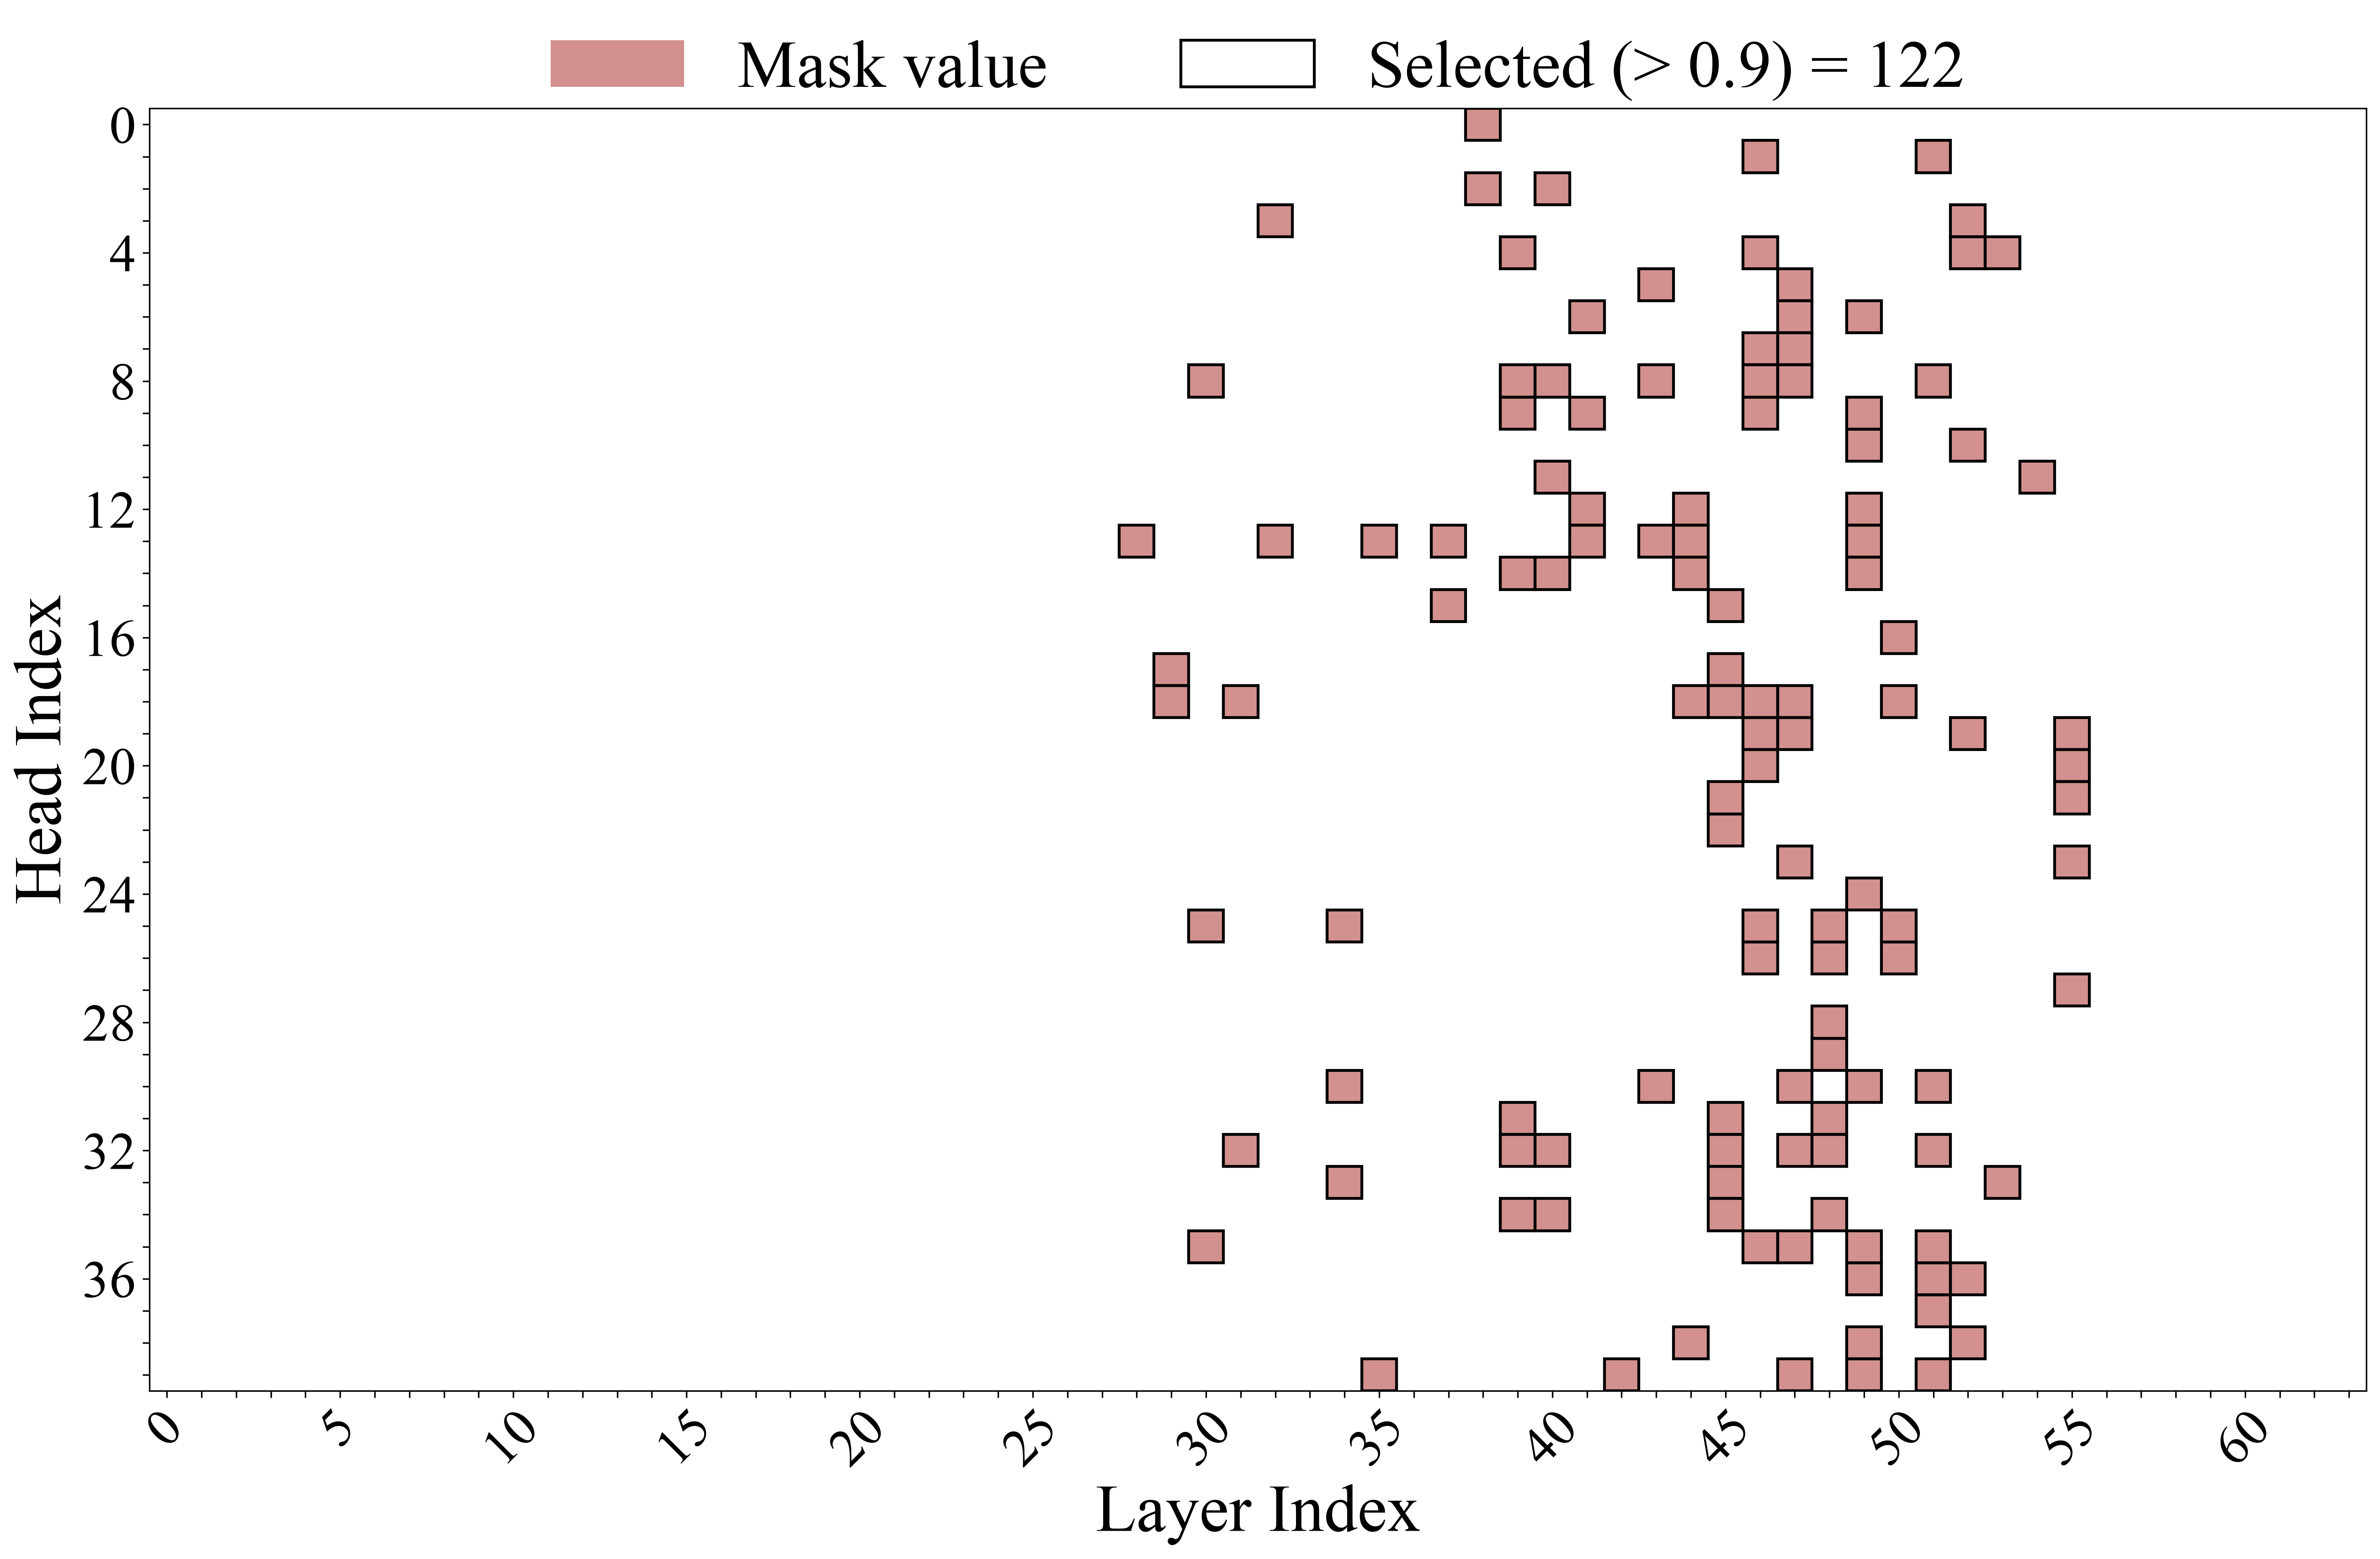

In [7]:
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import pyplot as plt
from matplotlib import patches

plt.rcParams["figure.dpi"] = 300
plt.rcParams["font.family"] = "Times New Roman"

SMALL_SIZE = 28
MEDIUM_SIZE = 35
BIGGER_SIZE = 40

plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=BIGGER_SIZE)
plt.rc("axes", labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=SMALL_SIZE)
plt.rc("figure", titlesize=BIGGER_SIZE)


def get_ticks(ticks, skip=5, offset=0):
    ret = []
    for i in ticks:
        actual_layer = i + offset
        if actual_layer % skip == 0:
            ret.append(str(actual_layer))
        else:
            ret.append("")
    return ret


_n_heads = mt.config.num_attention_heads
_n_layer = mt.n_layer

# Build continuous mask matrix: shape (n_heads, n_layer)
# Layers outside the optimized range stay 0.
function_mask = torch.zeros((_n_heads, _n_layer), dtype=torch.float32)
for i, layer_idx in enumerate(LAYERS):
    function_mask[:, layer_idx] = mask.values[i].detach().cpu()

# Create figure and axis
fig, ax = plt.subplots(figsize=(18, 12))

colors = ["white", "#BF625E"]
cmap = LinearSegmentedColormap.from_list("white_orange", colors, N=100)

ax.imshow(
    function_mask.numpy(),
    cmap=cmap,
    aspect="auto",
    vmin=0,
    vmax=1,
    alpha=0.7,
)

# Black border around selected heads (mask value > 0.5)
for layer_idx, head_idx in goal_heads:
    rect = patches.Rectangle(
        (layer_idx - 0.5, head_idx - 0.5),
        1,
        1,
        linewidth=1.5,
        edgecolor="black",
        facecolor="none",
    )
    ax.add_patch(rect)

plt.xlabel("Layer Index")
plt.ylabel("Head Index")
plt.xticks(
    ticks=range(_n_layer),
    labels=get_ticks(range(_n_layer)),
    rotation=45,
)
plt.yticks(
    ticks=range(_n_heads),
    labels=get_ticks(range(_n_heads), skip=4),
)

legend_elements = [
    mpatches.Patch(facecolor="#BF625E", alpha=0.7, label="Mask value"),
    mpatches.Patch(
        facecolor="white",
        edgecolor="black",
        linewidth=1.5,
        label=f"Selected (> {threshold}) = {len(goal_heads)}",
    ),
]
ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.1),
    ncol=2,
    fontsize=MEDIUM_SIZE,
    frameon=False,
)

plt.tight_layout()
plt.show()


In [8]:
import torch


from src.goals.head_loc_attn import (
    HeadMask,
    forward_with_src_replacement,
    get_o_proj_inputs_batch,
)
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt
from src.goals.goalscope import greedy_continue
from src.tokens import prepare_input
from src.trace import get_score

# ── Binary mask: 1.0 at selected heads, 0.0 everywhere else ─────────────────
_n_lt = len(LAYERS)
_n_h = mt.config.num_attention_heads
goal_mask = get_mask_bin(goal_heads)

print(
    f"Binary mask: {goal_mask.n_active()} active heads / {_n_lt * _n_h} total heads "
    f"({100 * goal_mask.n_active() / (_n_lt * _n_h):.2f}%)"
)

METRIC = "logit"  # "logit" or "prob"
MAX_NEW_TOKENS = 64
PATCH_ALL_TOKENS = True  # True → patch every generated token

_STOP_IDS = {mt.tokenizer.eos_token_id}


Binary mask: 122 active heads / 2560 total heads (4.77%)


In [9]:
from src.functional import generate_with_patch

test_prompt = """<|im_start|>system
You are short story writer<|im_end|>
<|im_start|>user
Write a short story for me.<|im_end|>
<|im_start|>assistant
There was once a king's son; nobody had so many or such beautiful books as he had. He could read about everything which had ever happened in this world, and see it all represented in the most beautiful pictures. He could get information about every nation and every country; but as to where the Garden of Paradise was to be found, not a word could he discover, and this was the very thing he thought most about. His grandmother had told him, when he was quite a little fellow and was about to begin his school life, that every flower in the Garden of Paradise was a delicious cake, and that the pistils were full of wine. In one flower history was written, in another geography or tables; you had only to eat the cake and you knew the lesson. The more you ate, the more history, geography and tables you knew. All this he believed then; but as he grew older and wiser and learnt more, he easily perceived that the delights of the Garden of Paradise must be far beyond all this."""

tokenized = prepare_input(test_prompt, mt, padding_side="left")
test_gen = generate_with_patch(
    mt,
    inputs=tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=256,
    do_sample=False,
    remove_prefix=True,
)[0]

rich_print(
    f"[bold]clean    [/bold] [white]{escape(test_prompt)}[/white]"
    f"[sea_green3]{escape(test_gen)}[/sea_green3]"
)

[transformers] You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


clean     <|im_start|>system
You are short story writer<|im_end|>
<|im_start|>user
Write a short story for me.<|im_end|>
<|im_start|>assistant
There was once a king's son; nobody had so many or such beautiful books as he had. He could read about everything 
which had ever happened in this world, and see it all represented in the most beautiful pictures. He could get 
information about every nation and every country; but as to where the Garden of Paradise was to be found, not a 
word could he discover, and this was the very thing he thought most about. His grandmother had told him, when he 
was quite a little fellow and was about to begin his school life, that every flower in the Garden of Paradise was a
delicious cake, and that the pistils were full of wine. In one flower history was written, in another geography or 
tables; you had only to eat the cake and you knew the lesson. The more you ate, the more history, geography and 
tables you knew. All this he believed then; but as he grew older and wiser and learnt more, he easily perceived 
that the delights of the Garden of Paradise must be far beyond all this. 

He was always thinking about it, and at last he said to his father, the king, "I will go out into the world and 
seek for the Garden of Paradise."

The king was very much alarmed at this proposal, and said, "My dear son, you cannot find the Garden of Paradise. It
is not to be found by any road that leads through this world."

But the prince said, "I must seek for it, nevertheless."

Then the king said, "If you will go, take with you my golden sword, my golden horse, and my golden crown, and if 
you meet with any difficulty, show them, and they may help you."

So the prince took these three things with him, and set out on his journey. He rode over hills and valleys, through
forests and meadows, and across rivers and seas, and met with many adventures.

One day he came to a great desert, and there he saw a little old woman sitting by the roadside. She looked very 
sad, and the prince asked her what was the matter. She said, "I am very thirsty, and I have nothing to drink." The 
prince gave her his golden cup, and she filled it with water from a spring near by and drank it. Then she said

In [10]:
from src.goals.goalscope import apply_goalscope
from src.goals.goalscope import _build_goalscope_prompt


goalscope_prompt = """<|im_start|>system
You are short story writer<|im_end|>
<|im_start|>user
You are in the middle of writing a short story. What should happen in the immediate future? Summarize the future events for me.<|im_end|>
<|im_start|>assistant"""

goalscope_results = apply_goalscope(
    prompt=test_prompt + test_gen,
    mt=mt,
    selected_heads=goal_heads,
    strategy="additive", alpha=0.3,
    # strategy="replace", alpha=1.0,
    steer_layer_range=(35, 46),
    max_new_tokens=64,
    n_steer_tokens="all",
    title="GoalScope",
    show=True,
    include_noncode=True,
    goalscope_prompt=goalscope_prompt,
    # save_path="letters.html"
)

GoalScope[additive]:   0%|          | 0/31 [00:00<?, ?it/s]

In [11]:
from src.functional import generate_with_patch

test_prompt = """<|im_start|>system
You are great at writing short poems.<|im_end|>
<|im_start|>user
Write a short poem for me.<|im_end|>
<|im_start|>assistant
"""

# prefix = """The quick white rabbit!"""
prefix = """Cold winds on my face"""
test_prompt = test_prompt + prefix

tokenized = prepare_input(test_prompt, mt, padding_side="left")
test_gen = generate_with_patch(
    mt,
    inputs=tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=256,
    do_sample=False,
    remove_prefix=True,
)[0]

rich_print(
    f"[bold]clean    [/bold] [white]{escape(test_prompt)}[/white]"
    f"[sea_green3]{escape(test_gen)}[/sea_green3]"
)

clean     <|im_start|>system
You are great at writing short poems.<|im_end|>
<|im_start|>user
Write a short poem for me.<|im_end|>
<|im_start|>assistant
Cold winds on my face,
Leaves whispering secrets,
Stars above, so vast and bright,
Guiding me through the night.

In this world of chaos and strife,
I find solace in the light,
A gentle reminder to keep moving,
To chase dreams with all my might.

In [12]:
from src.goals.goalscope import apply_goalscope
from src.goals.goalscope import _build_goalscope_prompt


goalscope_prompt = """<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
You are in the middle of writing a short poem. How are you planning to complete this line?<|im_end|>
<|im_start|>assistant"""

goalscope_results = apply_goalscope(
    prompt=test_prompt + test_gen,
    mt=mt,
    selected_heads=goal_heads,
    strategy="additive", alpha=0.3,
    # strategy="replace", alpha=1.0,
    steer_layer_range=(35, 46),
    max_new_tokens=64,
    n_steer_tokens="all",
    title="GoalScope",
    show=True,
    include_noncode=True,
    goalscope_prompt=goalscope_prompt,
    # save_path="letters.html"
)

GoalScope[additive]:   0%|          | 0/6 [00:00<?, ?it/s]

In [13]:
from src.functional import generate_with_patch

test_prompt = """<|im_start|>system
You are a chef who occasionally shares recipes in your personal blog.<|im_end|>
<|im_start|>user
Give me a recipe for making pasta.<|im_end|>
<|im_start|>assistant
"""

prefix=""
# prefix = """The quick white rabbit!"""
# prefix = """Cold winds on my face"""
test_prompt = test_prompt + prefix

tokenized = prepare_input(test_prompt, mt, padding_side="left")
test_gen = generate_with_patch(
    mt,
    inputs=tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=256,
    do_sample=False,
    remove_prefix=True,
)[0]

rich_print(
    f"[bold]clean    [/bold] [white]{escape(test_prompt)}[/white]"
    f"[sea_green3]{escape(test_gen)}[/sea_green3]"
)

clean     <|im_start|>system
You are a chef who occasionally shares recipes in your personal blog.<|im_end|>
<|im_start|>user
Give me a recipe for making pasta.<|im_end|>
<|im_start|>assistant
Certainly! Making pasta from scratch is a rewarding experience that allows you to control the quality and flavor of
your noodles. Here’s a simple recipe for classic egg pasta:

### Ingredients:
- 2 cups (250g) all-purpose flour, plus extra for dusting
- 3 large eggs
- A pinch of salt

### Equipment:
- Large mixing bowl
- Rolling pin
- Pasta cutter or sharp knife
- Boiling pot
- Colander

### Instructions:

#### Step 1: Prepare the Dough
1. **Mix Dry Ingredients**: In a large mixing bowl, combine the flour and salt. Make a well in the center of the 
flour.
2. **Add Eggs**: Crack the eggs into the well and beat them lightly with a fork.
3. **Knead the Dough**: Gradually incorporate the flour into the eggs by stirring with a fork until the mixture 
becomes too stiff to stir. Then, turn it out onto a floured surface and knead for about 5-7 minutes until the dough
is smooth and elastic. If the dough is too sticky, add a little more flour; if it's too dry, add a bit of water.

#### Step 2: Rest the Dough
1. **Cover and Let

In [14]:
_build_goalscope_prompt(mt)

'<|im_start|>system\nYou are a helpful assistant proficient in programming.<|im_end|>\n<|im_start|>user\nWhat are you doing at this line of the code. Keep your answer as brief as possible.<|im_end|>\n<|im_start|>assistant\n'

In [15]:
goalscope_prompt = """<|im_start|>system
You are a chef who occasionally shares recipes in your personal blog.<|im_end|>
<|im_start|>user
You are in the middle of writing a recipe. What is the next step?<|im_end|>
<|im_start|>assistant"""

goalscope_results = apply_goalscope(
    prompt=test_prompt + test_gen,
    mt=mt,
    selected_heads=goal_heads,
    strategy="additive", alpha=0.3,
    # strategy="replace", alpha=1.0,
    steer_layer_range=(35, 46),
    max_new_tokens=64,
    n_steer_tokens="all",
    title="GoalScope",
    show=True,
    include_noncode=True,
    goalscope_prompt=goalscope_prompt,
    # save_path="letters.html"
)

GoalScope[additive]:   0%|          | 0/19 [00:00<?, ?it/s]

In [16]:
from src.functional import generate_with_patch

test_prompt = """<|im_start|>system
You are a travel expert who helps people plan their trips.<|im_end|>
<|im_start|>user
Give me a travel plan for a weekend trip to Rome, Italy.<|im_end|>
<|im_start|>assistant
"""

prefix=""
# prefix = """The quick white rabbit!"""
# prefix = """Cold winds on my face"""
test_prompt = test_prompt + prefix

tokenized = prepare_input(test_prompt, mt, padding_side="left")
test_gen = generate_with_patch(
    mt,
    inputs=tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=256,
    do_sample=False,
    remove_prefix=True,
)[0]

rich_print(
    f"[bold]clean    [/bold] [white]{escape(test_prompt)}[/white]"
    f"[sea_green3]{escape(test_gen)}[/sea_green3]"
)

clean     <|im_start|>system
You are a travel expert who helps people plan their trips.<|im_end|>
<|im_start|>user
Give me a travel plan for a weekend trip to Rome, Italy.<|im_end|>
<|im_start|>assistant
Absolutely! Rome is a fantastic city with a rich history and vibrant culture, making it perfect for a weekend 
getaway. Here’s a detailed plan to help you make the most of your time there:

### Friday Night:
- **Arrival and Check-In:** Arrive in Rome and check into your hotel. If you're staying near the Colosseum or 
Piazza Navona, you'll be centrally located and close to many attractions.
- **Dinner:** Enjoy dinner at a traditional Roman trattoria. Try some classic Italian dishes like carbonara or osso
buco. For a more authentic experience, look for places that have been around for generations.

### Saturday Morning:
- **Colosseum and Roman Forum:** Start your day early to avoid crowds. The Colosseum is an iconic symbol of ancient
Rome, and the Roman Forum offers insights into daily life in the Roman Empire.
- **Palatine Hill:** After visiting the Colosseum, head to the Palatine Hill, which was once the center of Roman 
political life and home to many of Rome's emperors.

### Saturday Afternoon:
- **Pantheon:** Walk over to the Pantheon, one of the best-preserved buildings from ancient Rome. Take a moment to

In [17]:
goalscope_prompt = """<|im_start|>system
You are a travel expert who helps people plan their trips.<|im_end|>
<|im_start|>user
You are in the middle of writing a travel plan. What is the next step?<|im_end|>
<|im_start|>assistant"""

goalscope_results = apply_goalscope(
    prompt=test_prompt + test_gen,
    mt=mt,
    selected_heads=goal_heads,
    strategy="additive", alpha=0.3,
    # strategy="replace", alpha=1.0,
    steer_layer_range=(35, 46),
    max_new_tokens=64,
    n_steer_tokens="all",
    title="GoalScope",
    show=True,
    include_noncode=True,
    goalscope_prompt=goalscope_prompt,
    # save_path="letters.html"
)

GoalScope[additive]:   0%|          | 0/19 [00:00<?, ?it/s]

In [ ]:
from src.functional import generate_with_patch

test_prompt = """<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
What .<|im_end|>
<|im_start|>assistant
"""

prefix=""
# prefix = """The quick white rabbit!"""
# prefix = """Cold winds on my face"""
test_prompt = test_prompt + prefix

tokenized = prepare_input(test_prompt, mt, padding_side="left")
test_gen = generate_with_patch(
    mt,
    inputs=tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=256,
    do_sample=False,
    remove_prefix=True,
)[0]

rich_print(
    f"[bold]clean    [/bold] [white]{escape(test_prompt)}[/white]"
    f"[sea_green3]{escape(test_gen)}[/sea_green3]"
)

In [29]:
from src.functional import generate_with_patch

test_prompt = """<|im_start|>system
You are a helpful coding assistant.<|im_end|>
<|im_start|>user
"I need to accomplish the following: A Python implementation of git or another version control system..\nHere's a code template to work with:\n[TEMPLATE BEGIN]\nimport os\nfrom git import Repo\n\nrepo = Repo('/tmp/myrepo')\n\ndef add(paths):\n    repo.index.add(paths)\n\ndef commit(message):\n    repo.index.commit(message)\n\ndef checkout(branch):\n    repo.git.checkout(branch)\n\ndef merge(branch):\n    repo.merge(branch)\n\ndef clone(url):\n    Repo.clone_from(url, '/tmp/myrepo')\n\ndef push():\n    origin = repo.remote('origin')\n    origin.push()\n\ndef pull():\n    origin = repo.remote('origin')\n    origin.pull()\n\ndef init(path):\n    Repo.init(path)\n\ndef log():\n    repo.git.log()\n\ndef status():\n    repo.git.status()\n\ndef diff():\n    repo.git.diff()\n\ndef branch(name):\n    repo.git.branch(name)\n\nif __name__ == '__main__':\n    init('/tmp/myrepo')\n    add('README.md')\n    commit('Initial commit')\n\n## COMPLETE CODE HERE\n\n[TEMPLATE END]\n\nPlease complete the code by filling in the template in a way that will help me solve the task. Your response should contain only the code.\n<|im_end|>
<|im_start|>assistant
"""

prefix=""
test_prompt = test_prompt + prefix

tokenized = prepare_input(test_prompt, mt, padding_side="left")
test_gen = generate_with_patch(
    mt,
    inputs=tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=256,
    do_sample=False,
    remove_prefix=True,
)[0]

rich_print(
    f"[bold]clean    [/bold] [white]{escape(test_prompt)}[/white]"
    f"[sea_green3]{escape(test_gen)}[/sea_green3]"
)

clean     <|im_start|>system
You are a helpful coding assistant.<|im_end|>
<|im_start|>user
"I need to accomplish the following: A Python implementation of git or another version control system..
Here's a code template to work with:
[TEMPLATE BEGIN]
import os
from git import Repo

repo = Repo('/tmp/myrepo')

def add(paths):
    repo.index.add(paths)

def commit(message):
    repo.index.commit(message)

def checkout(branch):
    repo.git.checkout(branch)

def merge(branch):
    repo.merge(branch)

def clone(url):
    Repo.clone_from(url, '/tmp/myrepo')

def push():
    origin = repo.remote('origin')
    origin.push()

def pull():
    origin = repo.remote('origin')
    origin.pull()

def init(path):
    Repo.init(path)

def log():
    repo.git.log()

def status():
    repo.git.status()

def diff():
    repo.git.diff()

def branch(name):
    repo.git.branch(name)

if __name__ == '__main__':
    init('/tmp/myrepo')
    add('README.md')
    commit('Initial commit')

## COMPLETE CODE HERE

[TEMPLATE END]

Please complete the code by filling in the template in a way that will help me solve the task. Your response should
contain only the code.
<|im_end|>
<|im_start|>assistant
```python
import os
from git import Repo

repo = Repo('/tmp/myrepo')

def add(paths):
    repo.index.add(paths)

def commit(message):
    repo.index.commit(message)

def checkout(branch):
    repo.git.checkout(branch)

def merge(branch):
    repo.git.merge(branch)

def clone(url):
    Repo.clone_from(url, '/tmp/myrepo')

def push():
    origin = repo.remote('origin')
    origin.push()

def pull():
    origin = repo.remote('origin')
    origin.pull()

def init(path):
    Repo.init(path)

def log():
    for commit in repo.iter_commits():
        print(f"Commit: {commit.hexsha}\nAuthor: {commit.author}\nDate: {commit.committed_datetime}\nMessage: 
{commit.message}\n")

def status():
    print(repo.git.status())

def diff():
    print(repo.git.diff())

def branch(name):
    repo.git.branch(name)

if __name__ == '__main__':
    if not os.path.exists('/tmp/myrepo/.git'):
        init('/tmp/myrepo')
        with open('/tmp/myrepo/README.md', 'w') as f:
            f.write('# My Repository\n')
        add('README.md')
        commit('Initial commit')
   

In [ ]:
goalscope_prompt = """<|im_start|>system
You are a helpful coding assistant.<|im_end|>
<|im_start|>user
You are in the middle of implementing a user request. What is your next step?<|im_end|>
<|im_start|>assistant"""

goalscope_results = apply_goalscope(
    prompt=test_prompt + test_gen,
    mt=mt,
    selected_heads=goal_heads,
    strategy="additive", alpha=0.3,
    # strategy="replace", alpha=1.0,
    steer_layer_range=(35, 46),
    max_new_tokens=64,
    n_steer_tokens="all",
    title="GoalScope",
    show=True,
    include_noncode=True,
    goalscope_prompt=goalscope_prompt,
    # save_path="letters.html"
)

GoalScope[additive]:   0%|          | 0/30 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
g = [d['patched_gen'] for d in goalscope_results if d['pos']==496][0]
print(g)

Certainly! Once you have your travel plan, you can proceed to implement actions such as processing the collected data or information for further analysis. For example, you might want to send notifications or perform specific tasks like logging information to a file or database. Here's a simple example of how you could process the information by printing out


In [ ]:
# ── loaders for completion-mask results (scripts/clock/train_completion_mask.py) ──
from src.goals.oid_gaze import cache_root
from src.goals.head_loc_attn import HeadMask

COMPLETION_VERSION = "conditions"
# swap to "completion_mask_gaze" if you want the gaze-obj variant instead
MASK_KIND = "completion_mask"
COMPLETION_MASK_ROOT = os.path.join(cache_root(MODEL_NAME, COMPLETION_VERSION), MASK_KIND)


def list_completion_masks():
    if not os.path.isdir(COMPLETION_MASK_ROOT):
        return []
    items = [
        (t, os.path.join(COMPLETION_MASK_ROOT, t),
         os.path.getmtime(os.path.join(COMPLETION_MASK_ROOT, t)))
        for t in os.listdir(COMPLETION_MASK_ROOT)
        if os.path.isdir(os.path.join(COMPLETION_MASK_ROOT, t))
    ]
    return sorted(items, key=lambda x: x[2], reverse=True)


def load_completion_mask(tag=None):
    items = list_completion_masks()
    assert items, f"no {MASK_KIND} results under {COMPLETION_MASK_ROOT}"
    if tag is None:
        d = items[0][1]
    else:
        matches = [it for it in items if tag in it[0]]
        assert matches, f"no run under {COMPLETION_MASK_ROOT} contains tag {tag!r}"
        d = matches[0][1]
    ck = torch.load(os.path.join(d, "mask.pt"), map_location="cpu", weights_only=False)
    ck["dir"] = d
    return ck


def completion_mask_to_headmask(ck):
    layers = [int(x) for x in ck["layers"]]
    nH = ck["mask_values"].shape[1]
    hm = HeadMask(len(layers), nH)
    with torch.no_grad():
        hm.values.copy_(ck["mask_values"])
    return hm

def _tok(i):
    return mt.tokenizer.decode(i)

In [ ]:
# ── pick a mask and inspect it ──
# COMPLETION_MASK_TAG = None    # newest by mtime
COMPLETION_MASK_TAG = "lam10.0"   # completion_mask
# COMPLETION_MASK_TAG = "lam100.0"   # completion_mask_gaze

CK     = load_completion_mask(COMPLETION_MASK_TAG)
layers = [int(x) for x in CK["layers"]]
mv     = CK["mask_values"].numpy()
hist   = CK["history"]
meta   = CK["meta"]
sel_heads    = [tuple(int(z) for z in lh) for lh in CK["decision_heads"]]
thr    = float(meta.get("sel_threshold", 0.9))

print(f"[{os.path.basename(CK['dir'])}]")
print(f"  layers {layers[0]}-{layers[-1]} ({len(layers)} masked) · patch_tokens={CK['patch_tokens']} · "
      f"direction={meta['direction']} · same={meta['same']} · N={meta['n_pairs']}")
print(f"  {len(sel_heads)} decision heads (mask>{thr}) · "
      f"final train score={hist['train_score'][-1]:+.4f} · val score={hist['val_score'][-1]:+.4f}")
ranked = sorted(sel_heads, key=lambda lh: mv[layers.index(lh[0]), lh[1]], reverse=True)
print("  top decision heads:", [f"L{l}H{h}" for (l, h) in ranked[:15]])


AssertionError: no completion_mask results under results/multistep_clock/conditions/Qwen2.5-Coder-32B-Instruct/completion_mask

In [ ]:
# ── selected heads (mask > thr) as a set + a binary HeadMask for patching ──
SEL_THRESHOLD = 0.8
n_layer_total = mt.model.config.num_hidden_layers
n_heads_total = mv.shape[1]

full_mask = np.full((n_layer_total, n_heads_total), np.nan, dtype=float)
for li, L in enumerate(layers):
    full_mask[L] = mv[li]

sel_set   = {(int(l), int(h)) for l, h in np.argwhere(full_mask > SEL_THRESHOLD)}
sel_heads = sorted(sel_set)

# Default set used for interventions in §3–§5. The separator-analysis cells below overwrite
# this with filtered_sel_heads; seeding it here keeps §3–§5 runnable even if that step is skipped.
DECISION_HEADS = sel_heads

mask_bin = HeadMask(len(layers), n_heads_total)
with torch.no_grad():
    mask_bin.values.zero_()
    for (l, h) in sel_set:
        mask_bin.values[layers.index(l), h] = 1.0
print(f"mask_bin: {int(mask_bin.values.sum().item())} heads = 1.0  (binary @ thr {SEL_THRESHOLD})")
print(f"DECISION_HEADS: {len(DECISION_HEADS)} heads (default = sel_heads; override via the filter cell)")

mask_bin: 181 heads = 1.0  (binary @ thr 0.8)
DECISION_HEADS: 181 heads (default = sel_heads; override via the filter cell)


In [ ]:
# -- selected heads: does OV write at the pivot separate stay (ml) vs move-on (sl)? --
from torch.nn.functional import cosine_similarity as _cos
from src.goals.completion_pairs import build_completion_pairs
from src.goals.head_loc_attn import collect_head_steering_vecs
from src.tokens import prepare_input

N_DECISION = 100
PIVOT_POS = -2

# minimal pairs: source IS dest (same spec, ml vs sl differ only at the target line)
dec_pairs = build_completion_pairs(
    mt, n_pairs=N_DECISION, direction="both", same=True,
    patch_tokens=tuple(int(t) for t in CK["patch_tokens"]), seed=2024,
)
stay_prompts = [p.source.ml_prompt for p in dec_pairs]    # incomplete target  -> stay/continue
move_prompts = [p.source.sl_prompt for p in dec_pairs]    # complete target    -> moved_on
print(f"{len(dec_pairs)} minimal pairs; reading {len(sel_heads)} selected heads at pos {PIVOT_POS}")

# per-head OV write at the pivot for both situations (left-pad => -2 aligns across lengths)
stay_tok = prepare_input(stay_prompts, tokenizer=mt, padding_side="left")
move_tok = prepare_input(move_prompts, tokenizer=mt, padding_side="left")
_, stay_h = collect_head_steering_vecs(mt, stay_tok, sel_heads, [PIVOT_POS], return_individual_heads=True)
_, move_h = collect_head_steering_vecs(mt, move_tok, sel_heads, [PIVOT_POS], return_individual_heads=True)


rows = []
for (l, h) in sorted(sel_heads):
    stay = stay_h[(l, h)][:, 0, :].float()   # (N, n_embd)
    move = move_h[(l, h)][:, 0, :].float()   # (N, n_embd)
    per_pair = _cos(stay, move, dim=1)                       # (N,)  cos within each spec
    mean_vs_mean = _cos(stay.mean(0), move.mean(0), dim=0).item()
    rows.append((l, h, per_pair.mean().item(), per_pair.std().item(), mean_vs_mean))

rows.sort(key=lambda r: r[2])   # most-separating (lowest cosine) first
print(f"\n{'layer':>5} {'head':>5} {'per-pair cos (mean+/-std)':>26} {'mean-vs-mean cos':>18}")
for l, h, m, s, mm in rows:
    print(f"{l:5d} {h:5d} {m:>14.3f} +/-{s:<7.3f} {mm:>18.3f}")

  built 25/100 pairs (27 attempts)
  built 50/100 pairs (54 attempts)
  built 75/100 pairs (79 attempts)
  built 100/100 pairs (104 attempts)
built 100 pairs from 104 attempts
100 minimal pairs; reading 181 selected heads at pos -2

layer  head  per-pair cos (mean+/-std)   mean-vs-mean cos
   51     4          0.006 +/-0.340               -0.070
   44    28          0.120 +/-0.193                0.101
   31    10          0.129 +/-0.205                0.010
   47    31          0.155 +/-0.233                0.595
   13    22          0.174 +/-0.214                0.221
   40    32          0.177 +/-0.222                0.084
   48    26          0.178 +/-0.197                0.266
   14    25          0.179 +/-0.204                0.327
   48    28          0.181 +/-0.210                0.210
   51     2          0.207 +/-0.299                0.307
   28    13          0.228 +/-0.221                0.223
   43    16          0.246 +/-0.196                0.279
   38    29          0.24

In [ ]:
filtered_sel_heads = [
    (l, h)
    for (l, h), m, s, mm in zip(
        sel_heads, [r[2] for r in rows], [r[3] for r in rows], [r[4] for r in rows]
    )
    if m < 0.7
]
print(len(filtered_sel_heads), len(sel_heads))


#######################################################################
DECISION_HEADS = filtered_sel_heads
# PATCH_HEADS = sel_heads
#######################################################################
len(DECISION_HEADS)

140 181


140

In [ ]:
from src.goals.head_loc_attn import HeadMask
from src.utils import env_utils
import matplotlib.patches as mpatches
from scripts.clock.score_condition_heads import load_head_scores


# ── pick the scoring config to inspect ────────────────────────────────────────
Q_SPAN = 15
COMPARE_WITH = "mean"        # "mean" | "max"
TOP_K = 150
VERSION = "conditions"
# ──────────────────────────────────────────────────────────────────────────────
gaze_scores = load_head_scores(model=MODEL_NAME, version=VERSION, q_span=Q_SPAN, compare_with=COMPARE_WITH)["combined"]

# ── top-K gaze heads ──────────────────────────────────────────────────────────
# flat_idx = np.argsort(gaze_scores, axis=None)[::-1][:TOP_K]
LO_LAYER = 0
head_idx_to_gaze_scores = []
for layer_idx in range(LO_LAYER, gaze_scores.shape[0]):
    for head_idx in range(gaze_scores.shape[1]):
        head_idx_to_gaze_scores.append(((layer_idx, head_idx), gaze_scores[layer_idx, head_idx]))
head_idx_to_gaze_scores = sorted(head_idx_to_gaze_scores, key=lambda x: x[1], reverse=True)[:TOP_K]

gaze_heads = [(l, h) for (l, h), _ in head_idx_to_gaze_scores]
print(f"top-{TOP_K} gaze heads  (compare_with='{COMPARE_WITH}', q_span={Q_SPAN})  "
      f"score range [{gaze_scores[gaze_heads[-1]]:.3f}, {gaze_scores[gaze_heads[0]]:.3f}]")
for rank, (l, h) in enumerate(gaze_heads[:15], start=1):
    print(f"  {rank:2d}. L{l:2d} H{h:2d}  score={gaze_scores[l, h]:.3f}")
if TOP_K > 15:
    print(f"  ... (+ {TOP_K - 15} more)")

top-150 gaze heads  (compare_with='mean', q_span=15)  score range [2.579, 3.478]
   1. L53 H16  score=3.478
   2. L52 H23  score=3.464
   3. L40 H21  score=3.452
   4. L51 H13  score=3.451
   5. L36 H23  score=3.422
   6. L59 H34  score=3.364
   7. L34 H11  score=3.358
   8. L45 H12  score=3.293
   9. L48 H 8  score=3.277
  10. L51 H11  score=3.246
  11. L45 H11  score=3.222
  12. L48 H 5  score=3.217
  13. L50 H12  score=3.181
  14. L32 H23  score=3.175
  15. L53 H18  score=3.168
  ... (+ 135 more)


decision heads: 140  ·  gaze top-150: 150 in masked band
overlap (both): 14  ·  Jaccard within band = 0.051
  overlap heads: ['L25H18', 'L25H19', 'L40H0', 'L42H31', 'L43H29', 'L43H5', 'L44H13', 'L45H20', 'L45H23', 'L45H8', 'L46H29', 'L46H38', 'L46H8', 'L47H8']


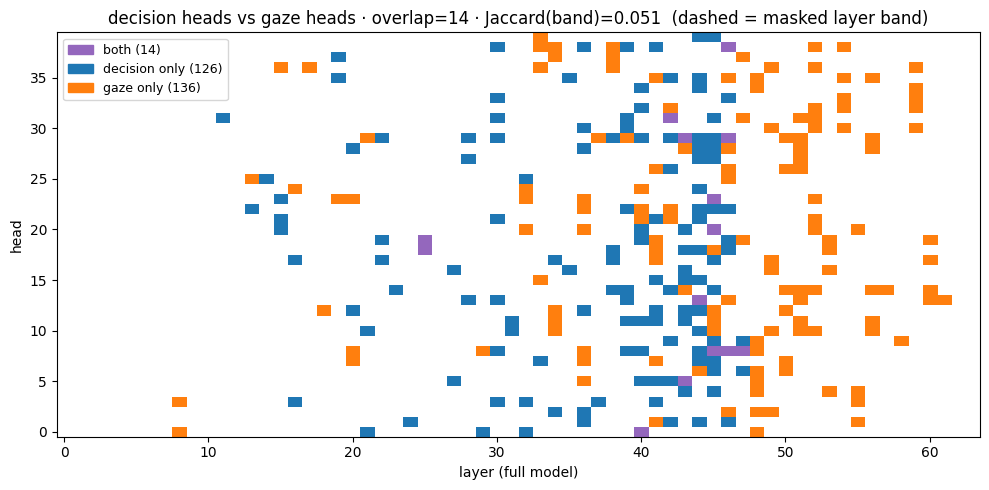

In [ ]:
# Plot the gaze heads with DECISION_HEADS overlaid
# needs `gaze_heads` (gaze-score cell) and `DECISION_HEADS` (§1 selection / filter cell).
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

gaze_set  = {(int(l), int(h)) for (l, h) in gaze_heads}
PATCH_SET = set(DECISION_HEADS)
both      = PATCH_SET & gaze_set
mask_only = PATCH_SET - gaze_set
gaze_only = gaze_set - PATCH_SET

# the mask can only select WITHIN its masked layer band — restrict gaze there for a fair
# Jaccard, but plot the full picture.
band = set(layers)
gaze_in_band = {(l, h) for (l, h) in gaze_set if l in band}
jac = len(both) / max(len(PATCH_SET | gaze_in_band), 1)
print(f"decision heads: {len(PATCH_SET)}  ·  gaze top-{len(gaze_set)}: "
      f"{len(gaze_in_band)} in masked band")
print(f"overlap (both): {len(both)}  ·  Jaccard within band = {jac:.3f}")
print("  overlap heads:", sorted(f"L{l}H{h}" for (l, h) in both))

# categorical grid: 0 none · 1 gaze-only · 2 decision-only · 3 both
cat = np.zeros((n_layer_total, n_heads_total))
for (l, h) in gaze_only: cat[l, h] = 1
for (l, h) in mask_only: cat[l, h] = 2
for (l, h) in both:      cat[l, h] = 3
cats_cmap = ListedColormap(["#ffffff", "#ff7f0e", "#1f77b4", "#9467bd"])

fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(cat.T, aspect="auto", cmap=cats_cmap, vmin=0, vmax=3,
          origin="lower", interpolation="nearest")
ax.axvline(layers[0] - 0.5, color="k", ls="--", lw=0.7)
ax.axvline(layers[-1] + 0.5, color="k", ls="--", lw=0.7)
ax.set_xlabel("layer (full model)"); ax.set_ylabel("head")
ax.set_title(f"decision heads vs gaze heads · overlap={len(both)} · "
             f"Jaccard(band)={jac:.3f}  (dashed = masked layer band)")
handles = [mpatches.Patch(color=c, label=lab) for c, lab in [
    ("#9467bd", f"both ({len(both)})"),
    ("#1f77b4", f"decision only ({len(mask_only)})"),
    ("#ff7f0e", f"gaze only ({len(gaze_only)})"),
]]
ax.legend(handles=handles, loc="upper left", fontsize=9)
fig.tight_layout(); plt.show()
